# 06 — Machine learning on the curve shape: extensions

Notebook 05 used scalar features of each curve ($\log A$, maximum indentation, adhesion, ...). This notebook asks what the **whole force–indentation curve** adds, and tests the robustness of the ML conclusions.

**What this notebook does**

1. builds **resampled force–indentation curves** (60 points on the normalised indentation, amplitude-normalised shape, $F_{max}$, $\delta_{max}$ and the force at fixed indentation 150 and 300 nm) and saves them in `results/` (tracked), so that everything after this step runs without the raw data;
2. studies the curve shape with **PCA** and checks what the leading components mean physically (exponent of the contact law, $F_{max}$, $\delta_{max}$, $\log A$);
3. runs **unsupervised clustering** (K-means, Gaussian mixture) on shape and scalar features and compares the clusters with line and region;
4. compares **classification** of the region from scalar features, from the shape only (amplitude removed) and from both;
5. checks whether $\log A$ is explained by **measurement covariates** (maximum indentation, noise, adhesion): a test of whether $A$ is a property of the cell or partly an artifact of the fit window;
6. adds **conformal prediction** to the region classifier: sets with guaranteed coverage and a quantification of the ambiguous curves;
7. computes **learning curves** (AUC versus number of training curves), to size future measurements;
8. builds a **shape-based anomaly detector** (PCA reconstruction error) and compares it with the Isolation Forest of notebook 05 on the same synthetic defects.

**What it does NOT do**

- it does not exclude any curve from the statistics of notebooks 03–04;
- it does not claim biological conclusions: all caveats of notebooks 03–05 hold (pseudo-replication, line ≡ session, pre-selected sample);
- it does not train deep networks: with 257 curves a neural model would not be supported by the data.

Region labels follow the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, IsolationForest
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict, cross_val_score
from sklearn.metrics import roc_auc_score, adjusted_rand_score, silhouette_score, r2_score
from sklearn.inspection import permutation_importance
import afm_tools as T

T.set_plot_style()
SEED = 20261016; RNG = np.random.default_rng(SEED)
fit = T.load_fit_table(); fit = fit[fit.fit_status == "ok"].reset_index(drop=True)
fit["rel_err_A"] = fit.A_err_nN_per_um_3over2 / fit.A_nN_per_um_3over2
summary = {}
print(len(fit), "curves")

257 curves


## 1. Resampled force–indentation curves

For every curve the baseline-corrected force is taken beyond the fitted contact point, the indentation $\delta=z_c-z$ is normalised by its maximum $\delta_{max}$, and the force normalised by $F_{max}$ is interpolated on 60 points $u=\delta/\delta_{max}\in[0.05,1]$. A pure Hertz curve gives $F/F_{max}=u^{3/2}$ whatever $A$ is: the shape isolates the *form* of the curve from its *amplitude*. If the raw-data cache exists the table is rebuilt, otherwise the tracked table is read.

rebuilt curves_resampled.csv
257 curves with shape


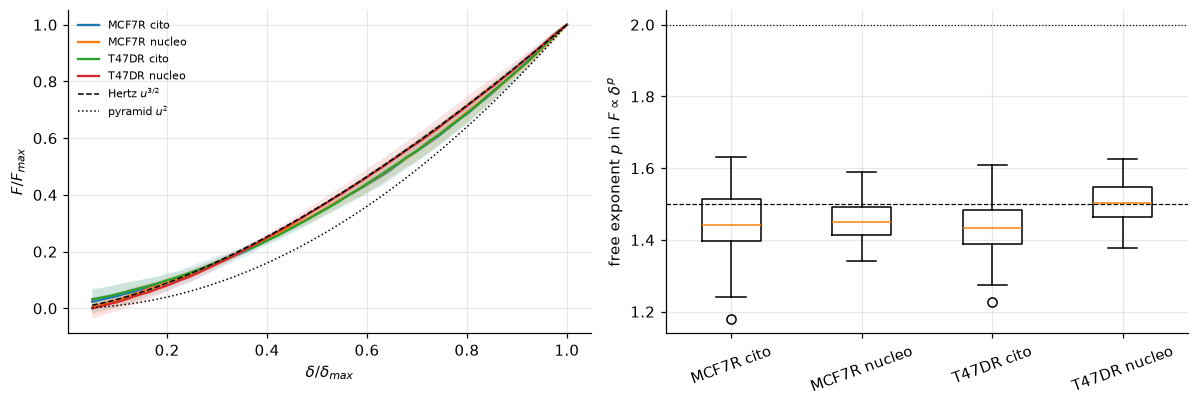

median free exponent: 1.47   [5,95]%: [1.34 1.57]


In [2]:
NU = 60; U = np.linspace(0.05, 1, NU); CURVES_PATH = T.RESULTS_DIR / "curves_resampled.csv"

def resample(z, f, cfg=T.NOMINAL):
    r = T.fit_curve(z, f, cfg, return_arrays=True)
    if r["fit_status"] != "ok": return None
    a = r["_arrays"]; zc = r["contact_z_fit_um"]; m = a["z"] < zc
    d = zc - a["z"][m]; F = gaussian_filter1d(a["fcorr"][m], sigma=5)
    o = np.argsort(d); d, F = d[o], F[o]; dmax, fmax = d.max(), max(F.max(), 1e-9)
    fixed = {f"F_at_{int(1000 * d0)}nm": (max(float(np.interp(d0, d, F)), 1e-3) if dmax >= d0 else np.nan) for d0 in (0.15, 0.30)}   # force at fixed indentation [nN]
    return dict(dmax_um=dmax, fmax_nN=fmax, **fixed, **{f"s{i:02d}": v for i, v in enumerate(np.interp(U * dmax, d, F) / fmax)})

if T.MANIFEST_PATH.exists():
    man = T.load_manifest(); rows = []
    for _, m in man.iterrows():
        z, f = T.read_curve(T.CODE_DIR / m["csv_path"]); r = resample(z, f)
        if r is not None: rows.append(dict(file_name=m["file_name"], group=m["group"], **r))
    curves = pd.DataFrame(rows); curves.to_csv(CURVES_PATH, index=False); print("rebuilt", CURVES_PATH.name)
else:
    curves = pd.read_csv(CURVES_PATH); print("read", CURVES_PATH.name)

SH = [f"s{i:02d}" for i in range(NU)]
df = fit.merge(curves[["file_name", "group", "dmax_um", "fmax_nN", "F_at_150nm", "F_at_300nm"] + SH], on=["file_name", "group"], suffixes=("", "_c"))
print(len(df), "curves with shape")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for g in T.GROUP_ORDER:
    s = df[df.group == g][SH].to_numpy(); m, sd = s.mean(0), s.std(0)
    ax[0].plot(U, m, label=T.short_group(g)); ax[0].fill_between(U, m - sd, m + sd, alpha=.12)
ax[0].plot(U, U ** 1.5, "k--", lw=1, label=r"Hertz $u^{3/2}$"); ax[0].plot(U, U ** 2, "k:", lw=1, label=r"pyramid $u^{2}$")
ax[0].set_xlabel(r"$\delta/\delta_{max}$"); ax[0].set_ylabel(r"$F/F_{max}$"); ax[0].legend(fontsize=7)
ax[1].boxplot([df[df.group == g].exponent_hat for g in T.GROUP_ORDER], tick_labels=[T.short_group(g) for g in T.GROUP_ORDER]); ax[1].axhline(1.5, c="k", ls="--", lw=.8); ax[1].axhline(2, c="k", ls=":", lw=.8)
ax[1].set_ylabel("free exponent $p$ in $F\\propto\\delta^p$"); plt.setp(ax[1].get_xticklabels(), rotation=20)
plt.tight_layout(); plt.show()
print("median free exponent:", df.exponent_hat.median().round(2), "  [5,95]%:", np.quantile(df.exponent_hat, [.05, .95]).round(2))
summary["exponent_hat_median"] = float(df.exponent_hat.median())

The median free exponent is **≈1.5**, i.e. the spherical Hertz value, and not the 2 expected for a perfectly pyramidal tip: the data do not support replacing the exponent. The spread (5–95%: see the printed range) shows that individual curves deviate from a pure power law, which is what the shape analysis below picks up.

## 2. PCA of the shape

PCA on the amplitude-normalised shapes: how many components describe the curves, and what do they mean physically?

explained variance: [0.599 0.229 0.039 0.028 0.017 0.016]  cumulative: [0.599 0.828 0.867 0.895 0.911 0.927]


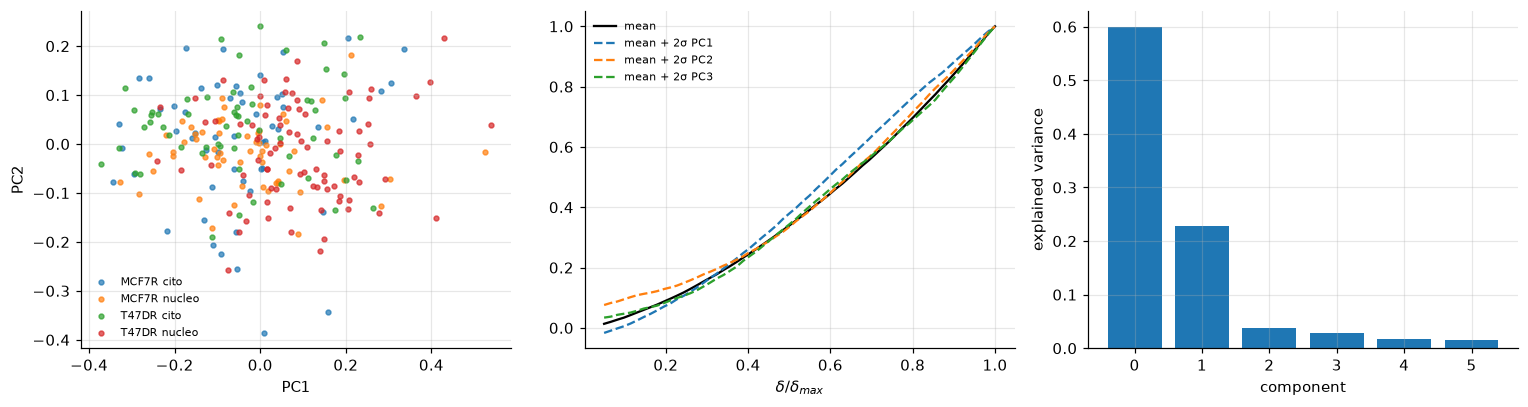

,free exponent,log Fmax,log dmax,logA,adhesion
PC1,0.65,-0.21,-0.14,0.17,-0.07
PC2,-0.49,0.19,-0.27,0.34,0.10
PC3,0.38,0.06,-0.02,0.03,0.11


In [3]:
Xs = df[SH].to_numpy(); pca = PCA(n_components=6).fit(Xs); Z = pca.transform(Xs)
print("explained variance:", pca.explained_variance_ratio_.round(3), " cumulative:", pca.explained_variance_ratio_.cumsum().round(3))
phys = {"free exponent": df.exponent_hat, "log Fmax": np.log(df.fmax_nN), "log dmax": np.log(df.dmax_um), "logA": df.logA, "adhesion": df.adhesion_nN}
cor = pd.DataFrame({k: [stats.spearmanr(Z[:, j], v)[0] for j in range(3)] for k, v in phys.items()}, index=["PC1", "PC2", "PC3"]).round(2)
summary["pca"] = dict(var=pca.explained_variance_ratio_.round(4).tolist(), spearman=cor.to_dict("index"))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for g in T.GROUP_ORDER:
    m = (df.group == g).to_numpy(); ax[0].scatter(Z[m, 0], Z[m, 1], s=10, label=T.short_group(g), alpha=.7)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=7)
ax[1].plot(U, pca.mean_, "k", label="mean")
for j in range(3): ax[1].plot(U, pca.mean_ + 2 * np.sqrt(pca.explained_variance_[j]) * pca.components_[j], ls="--", label=f"mean + 2σ PC{j + 1}")
ax[1].set_xlabel(r"$\delta/\delta_{max}$"); ax[1].legend(fontsize=7)
ax[2].bar(range(6), pca.explained_variance_ratio_); ax[2].set_xlabel("component"); ax[2].set_ylabel("explained variance"); plt.tight_layout(); plt.show()
cor

## 3. Unsupervised clustering

Do the curves cluster by line or region *without* using the labels? K-means and a Gaussian mixture on three feature sets (shape PCs; scalar features; both), with the adjusted Rand index (ARI) against line and region and the silhouette score. ARI near 0 means no correspondence.

In [4]:
SCAL = ["logA", "max_indentation_um", "adhesion_nN", "adhesion_work_nN_um", "exponent_hat"]
sets = {"shape PC1-3": Z[:, :3], "scalar": StandardScaler().fit_transform(df[SCAL]), "shape + scalar": np.c_[StandardScaler().fit_transform(Z[:, :3]), StandardScaler().fit_transform(df[SCAL])]}
rows = []
for nm, F in sets.items():
    for k in [2, 4]:
        for alg, lab in [("K-means", KMeans(k, n_init=10, random_state=SEED).fit_predict(F)), ("Gaussian mixture", GaussianMixture(k, n_init=5, random_state=SEED).fit_predict(F))]:
            rows.append(dict(features=nm, k=k, algorithm=alg, silhouette=silhouette_score(F, lab), ARI_line=adjusted_rand_score(df.cell_line, lab),
                             ARI_region=adjusted_rand_score(df.region, lab), ARI_group=adjusted_rand_score(df.group, lab)))
clu = pd.DataFrame(rows); summary["clustering"] = clu.round(3).to_dict("records"); clu.round(3)

,features,k,algorithm,silhouette,ARI_line,ARI_region,ARI_group
0,shape PC1-3,2,K-means,0.359,0.045,0.029,0.050
1,shape PC1-3,2,Gaussian mixture,0.263,0.005,-0.005,0.008
2,shape PC1-3,4,K-means,0.318,0.018,0.009,0.032
3,shape PC1-3,4,Gaussian mixture,0.287,0.032,0.032,0.047
4,scalar,2,K-means,0.308,0.010,0.157,0.100
5,scalar,2,Gaussian mixture,0.320,-0.003,0.211,0.106
6,scalar,4,K-means,0.273,0.032,0.175,0.149
7,scalar,4,Gaussian mixture,0.109,-0.005,0.090,0.067
8,shape + scalar,2,K-means,0.222,0.005,0.163,0.106
9,shape + scalar,2,Gaussian mixture,0.235,-0.000,0.189,0.089


## 4. Classification of the region: scalar, shape, or both

Per line, 5-fold stratified CV repeated 5 times, logistic model. Three feature sets: scalar (as in notebook 05), **shape only** (PCA of the amplitude-normalised curve: no $A$, no $F_{max}$), and both. If the shape alone separates the regions, the information is not just in the stiffness.

In [5]:
def cv_auc(model, X, y, n_rep=5):
    return np.mean([roc_auc_score(y, cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r), method="predict_proba")[:, 1]) for r in range(n_rep)])

MECH = ["logA", "max_indentation_um", "adhesion_nN", "adhesion_work_nN_um"]
logit = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
shape_model = lambda: make_pipeline(StandardScaler(), PCA(5), LogisticRegression(max_iter=2000))
rows = []
for l in ["MCF7R", "T47DR"]:
    d = df[df.cell_line == l].reset_index(drop=True); y = (d.region == "nucleo").astype(int).to_numpy()
    both = np.c_[d[MECH].to_numpy(), d[SH].to_numpy()]
    rows.append(dict(line=l, scalar=cv_auc(logit(), d[MECH].to_numpy(), y), shape_only=cv_auc(shape_model(), d[SH].to_numpy(), y),
                     both=cv_auc(make_pipeline(StandardScaler(), PCA(8), LogisticRegression(max_iter=2000)), both, y),
                     random_forest_shape=cv_auc(RandomForestClassifier(300, min_samples_leaf=3, random_state=SEED), d[SH].to_numpy(), y, 2)))
cls = pd.DataFrame(rows).set_index("line"); summary["classification_shape"] = cls.round(4).to_dict("index"); cls.round(3)

,scalar,shape_only,both,random_forest_shape
line,,,,
MCF7R,0.951,0.617,0.962,0.807
T47DR,0.626,0.759,0.773,0.757


## 5. Is $\log A$ just a re-expression of the indentation depth?

The curves end at an (almost) constant setpoint force, so the maximum indentation is $\delta_{max}\approx(F_{max}/A)^{2/3}$: **$\delta_{max}$ is a function of $A$**. A strong negative correlation between $\log A$ and $\delta_{max}$ is therefore expected by construction and is *not* by itself evidence of an artifact; likewise, adjusting $\Delta$ for $\delta_{max}$ would remove the effect trivially (the covariate contains the outcome). We show the numbers to document this redundancy, and then run a test that does not rely on the model: the **force at fixed indentation depth** $F(\delta_0)$ (150 and 300 nm), which needs no power-law fit and no choice of window. If the nucleus is softer, $F(\delta_0)$ must be smaller in the nucleus.

In [6]:
COV_ID = ["baseline_noise_pN", "baseline_slope_nN_per_um", "snr"]; COV_COUP = ["max_indentation_um", "adhesion_nN", "exponent_hat"]
rows = [dict(group=T.short_group(g), **{c: stats.spearmanr(df[df.group == g].logA, df[df.group == g][c])[0] for c in COV_ID + COV_COUP}) for g in T.GROUP_ORDER]
corr = pd.DataFrame(rows).set_index("group"); summary["spearman_logA_vs_covariates"] = corr.round(3).to_dict("index")
print("Spearman of logA vs covariates, within group (max_indentation is a function of A at fixed setpoint):"); display(corr.round(2))
cvk = KFold(5, shuffle=True, random_state=SEED); res = {}
for nm, cols in [("instrument only", COV_ID), ("with max indentation", COV_COUP + COV_ID)]:
    for mdl_nm, mdl in [("ridge", make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 2, 20)))), ("random forest", RandomForestRegressor(300, min_samples_leaf=5, random_state=SEED))]:
        res[(nm, mdl_nm)] = cross_val_score(mdl, df[cols], df.logA, cv=cvk, scoring="r2").mean()
r2 = pd.Series(res).unstack().round(3); summary["r2_logA_from_covariates"] = r2.to_dict("index"); print("CV R2 of logA from covariates:"); display(r2)

Spearman of logA vs covariates, within group (max_indentation is a function of A at fixed setpoint):


,baseline_noise_pN,baseline_slope_nN_per_um,snr,max_indentation_um,adhesion_nN,exponent_hat
group,,,,,,
MCF7R cito,0.12,-0.01,0.20,-0.91,0.03,-0.10
MCF7R nucleo,-0.13,0.05,0.17,-0.88,0.05,0.22
T47DR cito,-0.05,-0.25,0.17,-0.95,0.20,-0.21
T47DR nucleo,-0.24,-0.04,0.08,-0.95,0.26,0.06


CV R2 of logA from covariates:


,random forest,ridge
instrument only,-0.067,-0.042
with max indentation,0.948,0.934


In [7]:
# model-independent check: nucleus - cytoplasm difference of the log force at fixed indentation
rows = []
for l in ["MCF7R", "T47DR"]:
    for col, lab_ in [("logA", "log A (fit)"), ("F_at_150nm", "log F(150 nm)"), ("F_at_300nm", "log F(300 nm)")]:
        d = df[df.cell_line == l].dropna(subset=[col]); v = d[col] if col == "logA" else np.log(d[col])
        xn, xc = v[d.region == "nucleo"].to_numpy(), v[d.region == "cito"].to_numpy(); bm = T.bootstrap_stat(xn, np.mean, 5000, 1) - T.bootstrap_stat(xc, np.mean, 5000, 2)
        rows.append(dict(line=l, observable=lab_, n_cito=len(xc), n_nucleo=len(xn), delta=xn.mean() - xc.mean(), lo95=np.quantile(bm, .025), hi95=np.quantile(bm, .975),
                         p_welch=stats.ttest_ind(xn, xc, equal_var=False).pvalue, p_mw=stats.mannwhitneyu(xn, xc).pvalue))
fixed = pd.DataFrame(rows).set_index(["line", "observable"]); summary["delta_fixed_indentation"] = {f"{k[0]}|{k[1]}": v for k, v in fixed.round(5).to_dict("index").items()}; fixed.round(4)

n_cito  n_nucleo   delta    lo95    hi95  p_welch    p_mw
line  observable                                                              
MCF7R log A (fit)        55        60 -0.8139 -0.9636 -0.6614   0.0000  0.0000
      log F(150 nm)      55        60 -0.7236 -0.9592 -0.4468   0.0000  0.0000
      log F(300 nm)      55        60 -0.7639 -0.9140 -0.6102   0.0000  0.0000
T47DR log A (fit)        59        83 -0.2468 -0.4327 -0.0627   0.0114  0.0034
      log F(150 nm)      59        83 -0.5922 -0.8904 -0.3126   0.0001  0.0004
      log F(300 nm)      59        80 -0.3506 -0.5251 -0.1751   0.0002  0.0005

If the sign and the rough size of $\Delta$ are the same for $\log F(\delta_0)$ and for $\log A$ (and the intervals exclude zero), the nucleus–cytoplasm result of notebooks 03–04 does not depend on the power-law model or on the fit window. Note that $\log F(\delta_0)\approx\log A+\tfrac32\log\delta_0$ for a Hertz curve, so for $\delta_0$ fixed the two shifts should be close.

## 6. Conformal prediction for the region classifier

A point classifier gives only a probability. **Split conformal prediction** gives, for each curve, a *set* of labels (`{cito}`, `{nucleo}`, both, or none) with the guarantee that the true label is inside with probability $\ge1-\alpha$ if the data are exchangeable. We use the random-forest probabilities, 40% of the curves for calibration, 200 random splits, and report the empirical coverage, the fraction of singleton sets (decisive) and of two-label sets (ambiguous).

In [8]:
def conformal(d, alpha, n_split=200):
    y = (d.region == "nucleo").astype(int).to_numpy(); X_ = d[MECH].to_numpy(); out = []
    for s in range(n_split):
        rg = np.random.default_rng(s); idx = rg.permutation(len(y)); ncal = int(.4 * len(y)); cal, rest = idx[:ncal], idx[ncal:]
        ntr = int(.6 * len(rest)); tr, te = rest[:ntr], rest[ntr:]
        m = RandomForestClassifier(200, min_samples_leaf=3, random_state=s).fit(X_[tr], y[tr])
        sc = 1 - m.predict_proba(X_[cal])[np.arange(ncal), y[cal]]; q = np.quantile(sc, min(1, np.ceil((ncal + 1) * (1 - alpha)) / ncal))
        p = m.predict_proba(X_[te]); inset = (1 - p) <= q        # label k is in the set if its score <= q
        out.append((inset[np.arange(len(te)), y[te]].mean(), (inset.sum(1) == 1).mean(), (inset.sum(1) == 2).mean(), (inset.sum(1) == 0).mean()))
    return np.mean(out, 0)
rows = []
for l in ["MCF7R", "T47DR"]:
    d = df[df.cell_line == l].reset_index(drop=True)
    for alpha in [0.2, 0.1]:
        c = conformal(d, alpha, 100); rows.append(dict(line=l, target=1 - alpha, coverage=c[0], singleton=c[1], both_labels=c[2], empty=c[3]))
conf = pd.DataFrame(rows); summary["conformal"] = conf.round(3).to_dict("records"); conf.round(3)

,line,target,coverage,singleton,both_labels,empty
0,MCF7R,0.8,0.828,0.914,0.023,0.062
1,MCF7R,0.9,0.927,0.790,0.208,0.001
2,T47DR,0.8,0.798,0.509,0.491,0.000
3,T47DR,0.9,0.915,0.249,0.751,0.000


Coverage should be at or above the target; the fraction of two-label sets is the honest measure of how many curves cannot be assigned a region at that confidence. In T47DR, where the effect is small, most sets are expected to be ambiguous.

## 7. Learning curves

How many curves are needed? AUC of the logistic classifier (scalar features) on a fixed test fold, as a function of the number of training curves per class.

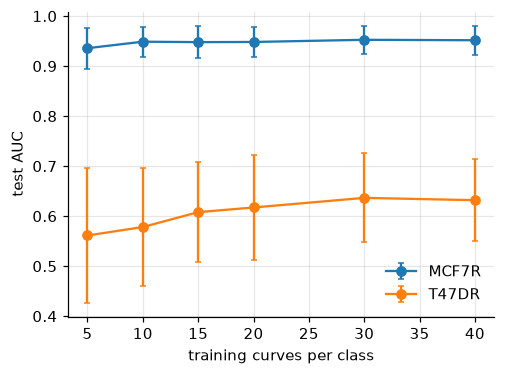

MCF7R         T47DR       
     mean     sd   mean     sd
5   0.936  0.041  0.561  0.135
10  0.949  0.030  0.578  0.117
15  0.948  0.033  0.608  0.101
20  0.948  0.030  0.617  0.105
30  0.953  0.028  0.637  0.089
40  0.952  0.029  0.632  0.082

In [9]:
def learning_curve(l, sizes, n_rep=40):
    d = df[df.cell_line == l].reset_index(drop=True); y = (d.region == "nucleo").astype(int).to_numpy(); X_ = d[MECH].to_numpy(); out = {n: [] for n in sizes}
    for r in range(n_rep):
        rg = np.random.default_rng(r); te = np.r_[rg.choice(np.flatnonzero(y == 0), 15, replace=False), rg.choice(np.flatnonzero(y == 1), 15, replace=False)]
        pool0, pool1 = [i for i in np.flatnonzero(y == 0) if i not in te], [i for i in np.flatnonzero(y == 1) if i not in te]
        for n in sizes:
            tr = np.r_[rg.choice(pool0, n, replace=False), rg.choice(pool1, n, replace=False)]
            out[n].append(roc_auc_score(y[te], logit().fit(X_[tr], y[tr]).predict_proba(X_[te])[:, 1]))
    return pd.DataFrame({n: (np.mean(v), np.std(v)) for n, v in out.items()}, index=["mean", "sd"]).T
sizes = [5, 10, 15, 20, 30, 40]; lc = {l: learning_curve(l, sizes) for l in ["MCF7R", "T47DR"]}
fig, ax = plt.subplots(figsize=(5, 3.6))
for l, t in lc.items(): ax.errorbar(t.index, t["mean"], t["sd"], marker="o", capsize=2, label=l)
ax.set_xlabel("training curves per class"); ax.set_ylabel("test AUC"); ax.legend(); plt.show()
summary["learning_curve"] = {l: t.round(3).to_dict("index") for l, t in lc.items()}; pd.concat(lc, axis=1).round(3)

## 8. Shape-based anomaly detector

Notebook 05 detected defects from scalar fit features. A detector working on the **curve shape** may see what the scalars miss (e.g. `wrong_slope`): PCA is trained on the real shapes, and the anomaly score is the **reconstruction error** (a linear autoencoder). It is evaluated on the same 5 synthetic defects at 5% false positives and compared with an Isolation Forest on the scalar features of notebook 05.

In [10]:
DEFECTS = ["no_contact", "saturation", "huge_noise", "jump", "wrong_slope"]
def synth_curve(src, defect, rg, n=5000, misfit=0.06):
    A, noise, slope, fmax = src.A_nN_per_um_3over2, src.baseline_noise_pN / 1e3, src.baseline_slope_nN_per_um, src.fmax_nN
    dmax = (fmax / A) ** (2 / 3); z0, zr = -9.4, 6.0
    zc = max(z0 - rg.uniform(.55, .85) * zr, z0 - zr + dmax + 0.05); z = np.linspace(z0, zc - dmax, n)
    p, noise_eff = 1.5, noise
    if defect == "wrong_slope": p = rg.choice([0.7, 2.6])
    if defect == "huge_noise": noise_eff = noise * rg.uniform(8, 20)
    d = np.clip(zc - z, 0, None); eps = gaussian_filter1d(rg.standard_normal(n), sigma=0.02 * n); eps /= eps.std()
    F = (A * d ** p if defect != "wrong_slope" else fmax * (d / max(d.max(), 1e-9)) ** p) * (1 + misfit * eps)
    if defect == "no_contact": F = 0.01 * F
    F = F + slope * (z - z0) + noise_eff * rg.standard_normal(n)
    if defect == "jump": i = rg.integers(int(n * .8), int(n * .97)); F[i:] += rg.choice([-1, 1]) * rg.uniform(.2, .5) * fmax
    if defect == "saturation": F = np.minimum(F, rg.uniform(.4, .6) * fmax)
    return z, F

N_SYN = 600; rg = np.random.default_rng(SEED); labels = np.array(["ok"] * N_SYN, dtype=object); bad = rg.choice(N_SYN, int(.1 * N_SYN), replace=False); labels[bad] = np.resize(DEFECTS, len(bad))
SC = ["fit_r2", "fit_rmse_rel", "snr", "n_fit_points", "max_indentation_um", "baseline_noise_pN", "baseline_slope_nN_per_um", "jump_score", "sat_fraction", "contact_shift_rel", "exponent_hat", "logA", "rel_err_A"]
rows = []
for i in range(N_SYN):
    z, F = synth_curve(df.iloc[rg.integers(len(df))], labels[i] if labels[i] != "ok" else None, rg); r = T.fit_curve(z, F, return_arrays=True); rs = resample(z, F) if r["fit_status"] == "ok" else None
    if rs is None: rows.append(dict(defect=labels[i], failed=True)); continue
    sc = {k: r.get(k, np.nan) for k in SC if k not in ("logA", "rel_err_A")}; sc["logA"] = np.log(r["A_nN_per_um_3over2"]); sc["rel_err_A"] = r["A_err_nN_per_um_3over2"] / r["A_nN_per_um_3over2"]
    rows.append(dict(defect=labels[i], failed=False, **sc, **{k: rs[k] for k in SH}))
syn = pd.DataFrame(rows); print(syn.defect.value_counts().to_dict(), "| failed fits:", int(syn.failed.sum()))

{'ok': 540, 'jump': 12, 'saturation': 12, 'huge_noise': 12, 'no_contact': 12, 'wrong_slope': 12} | failed fits: 24


In [11]:
ok = syn[~syn.failed].replace([np.inf, -np.inf], np.nan).dropna(subset=SC + SH)
good = ok[ok.defect == "ok"]; tr = good.sample(frac=.5, random_state=SEED); test = ok.drop(tr.index)
real_sc = df[SC].replace([np.inf, -np.inf], np.nan).dropna()
def pca_score(model, X): return ((X - model.inverse_transform(model.transform(X))) ** 2).sum(1)
def fpr_thr(scores_cv): return np.quantile(scores_cv, .95)
# detector A: PCA reconstruction error on the shape, trained on good synthetic shapes (domain-matched, as in notebook 05)
def cv_pca_scores(X, k=3):
    out = np.zeros(len(X))
    for a, b in KFold(5, shuffle=True, random_state=SEED).split(X): out[b] = pca_score(PCA(k).fit(X[a]), X[b])
    return out
iso = lambda: make_pipeline(QuantileTransformer(n_quantiles=200, output_distribution="normal"), IsolationForest(n_estimators=300, random_state=SEED))
def cv_iso_scores(X):
    out = np.zeros(len(X))
    for a, b in KFold(5, shuffle=True, random_state=SEED).split(X): out[b] = -iso().fit(X[a]).score_samples(X[b])
    return out
Xtr_sh, Xte_sh = tr[SH].to_numpy(), test[SH].to_numpy(); Xtr_sc, Xte_sc = tr[SC].to_numpy(), test[SC].to_numpy()
pc = PCA(3).fit(Xtr_sh); s_pca = pca_score(pc, Xte_sh); thr_pca = fpr_thr(cv_pca_scores(Xtr_sh))
isof = iso().fit(Xtr_sc); s_iso = -isof.score_samples(Xte_sc); thr_iso = fpr_thr(cv_iso_scores(Xtr_sc))
# combined: shape + scalar through the same Isolation Forest
Xtr_b, Xte_b = np.c_[Xtr_sc, Xtr_sh], np.c_[Xte_sc, Xte_sh]; isob = iso().fit(Xtr_b); s_b = -isob.score_samples(Xte_b); thr_b = fpr_thr(cv_iso_scores(Xtr_b))
isbad = (test.defect != "ok").to_numpy(); rows = {}
for d in DEFECTS:
    m = (test.defect == d).to_numpy(); tot = (syn.defect == d).sum(); failed = int(syn[(syn.defect == d)].failed.sum()); n_ok = m.sum()
    rows[d] = dict(n=tot, failed_fit=failed, shape_PCA=(failed + (s_pca[m] > thr_pca).sum()) / tot, scalar_IF=(failed + (s_iso[m] > thr_iso).sum()) / tot, shape_scalar_IF=(failed + (s_b[m] > thr_b).sum()) / tot)
eff = pd.DataFrame(rows).T
auc = dict(shape_PCA=roc_auc_score(isbad, s_pca), scalar_IF=roc_auc_score(isbad, s_iso), shape_scalar_IF=roc_auc_score(isbad, s_b))
fpr = dict(shape_PCA=float((s_pca[~isbad] > thr_pca).mean()), scalar_IF=float((s_iso[~isbad] > thr_iso).mean()), shape_scalar_IF=float((s_b[~isbad] > thr_b).mean()))
summary["shape_anomaly"] = dict(auc=auc, fpr=fpr, efficiency=eff.round(3).to_dict("index")); print("AUC:", {k: round(v, 3) for k, v in auc.items()}, " FPR:", {k: round(v, 3) for k, v in fpr.items()}); eff.round(2)

AUC: {'shape_PCA': 0.973, 'scalar_IF': 0.924, 'shape_scalar_IF': 0.98}  FPR: {'shape_PCA': 0.085, 'scalar_IF': 0.044, 'shape_scalar_IF': 0.048}


,n,failed_fit,shape_PCA,scalar_IF,shape_scalar_IF
no_contact,12.0,12.0,1.00,1.00,1.00
saturation,12.0,0.0,1.00,1.00,1.00
huge_noise,12.0,12.0,1.00,1.00,1.00
jump,12.0,0.0,1.00,0.83,1.00
wrong_slope,12.0,0.0,0.67,0.50,0.67


real curves flagged by shape detector: 13  also flagged by the notebook-05 Isolation Forest: 5


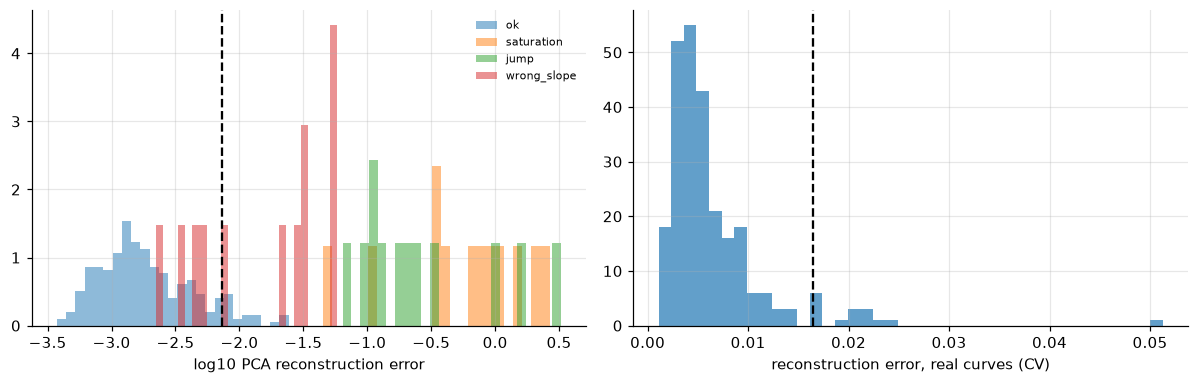

In [12]:
# real curves: shape-based reconstruction error, cross-validated, most anomalous ones
real_sh = df[SH].to_numpy(); rs_cv = cv_pca_scores(real_sh); flag = rs_cv > np.quantile(rs_cv, .95)
real_out = df[["file_name", "group"]].copy(); real_out["group"] = real_out.group.map(T.short_group); real_out["shape_recon_error"] = rs_cv; real_out["flag_shape"] = flag
try:
    s5 = pd.read_csv(T.RESULTS_DIR / "05_real_anomaly_scores.csv")[["file_name", "flag_iso", "flag_maha"]]; real_out = real_out.merge(s5, on="file_name", how="left")
    both = int((real_out.flag_shape & real_out.flag_iso.fillna(False).astype(bool)).sum()); print("real curves flagged by shape detector:", int(flag.sum()), " also flagged by the notebook-05 Isolation Forest:", both)
    summary["real_flagged_shape"] = int(flag.sum()); summary["real_flagged_shape_and_if"] = both
except Exception as e: print("notebook 05 scores not found:", e)
real_out.to_csv(T.RESULTS_DIR / "06_real_shape_anomaly.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for d in ["ok"] + DEFECTS:
    m = (test.defect == d).to_numpy()
    if m.sum(): ax[0].hist(np.log10(s_pca[m] + 1e-6), bins=25, alpha=.5, density=True, label=d)
ax[0].axvline(np.log10(thr_pca + 1e-6), c="k", ls="--"); ax[0].set_xlabel("log10 PCA reconstruction error"); ax[0].legend(fontsize=7)
ax[1].hist(rs_cv, bins=40, alpha=.7); ax[1].axvline(np.quantile(rs_cv, .95), c="k", ls="--"); ax[1].set_xlabel("reconstruction error, real curves (CV)")
plt.tight_layout(); plt.show()
json.dump(summary, open(T.RESULTS_DIR / "06_summary.json", "w"), indent=1, default=float)

## Interpretation and limits

- **Contact law.** The median free exponent is ≈1.5 (spherical Hertz) with a broad spread: the model of notebooks 02–04 is adequate on average and individual curves deviate from it.
- **Clustering.** Without labels the curves do not separate by line (ARI ≈ 0), and only weakly by region on the scalar features (ARI up to ≈ 0.2): the groups overlap, as expected for effect sizes of about one standard deviation (MCF7R) or less (T47DR).
- **Shape versus scalar.** In MCF7R the region is carried by the amplitude (AUC 0.95 from scalar features, 0.62 from the shape alone). In T47DR the opposite holds: the shape alone gives AUC ≈ 0.76 against 0.63 for the scalar features. The shape of the curve in T47DR therefore contains information on the region that $A$ does not; it could reflect a real difference in the contact law (cell/nucleus geometry, thickness) but also a dependence on the contact-point estimate, so it needs checking on the raw curves before any interpretation.
- **$\log A$ and indentation depth.** The ≈ −0.9 correlation of $\log A$ with the maximum indentation is a consequence of the constant setpoint force, not an artifact by itself; the covariate regression and any adjusted $\Delta$ are circular for the same reason. The model-independent test of the force at fixed indentation confirms the result of notebooks 03–04: the nucleus is softer in both lines ($\Delta\log F(300\text{ nm})=-0.76$ for MCF7R and $-0.35$ for T47DR, intervals excluding zero), so the conclusion does not depend on the power-law model or on the fit window. For T47DR the effect is clearer with $F(\delta_0)$ ($p\approx10^{-4}$) than with $\log A$ ($p\approx0.01$), which suggests that the weaker evidence of the fit parameter partly reflects the noise of the two-parameter fit rather than a weaker effect.
- **Conformal prediction.** Sets have the promised coverage. In MCF7R most curves get a single label; in T47DR at 90% confidence about three quarters of the sets contain both labels, i.e. the region cannot be assigned from these features for most curves.
- **Learning curves.** MCF7R reaches AUC ≈ 0.95 with about 10 curves per class and then saturates; T47DR stays around 0.6 and improves only slowly: for T47DR more independent cells, not a better model, are needed.
- **Shape anomaly detector.** PCA reconstruction error detects the injected defects at least as well as the scalar Isolation Forest (AUC 0.97 vs 0.92, `wrong_slope` 0.67 vs 0.50), but its false-positive rate on the synthetic test set is 8.5% instead of 5%, and with 12 defects per type the differences between detectors are within the statistical uncertainty. The real curves it flags (13, of which 5 also by the notebook-05 Isolation Forest) are listed in `results/06_real_shape_anomaly.csv` for visual inspection; none is excluded.
- All caveats of notebooks 03–05 apply: pseudo-replication, line ≡ session, pre-selected sample; CV scores of curves from the same cell are optimistic.

## Output produced and next step

```text
results/curves_resampled.csv        60-point amplitude-normalised force–indentation curves, Fmax, dmax (tracked)
results/06_summary.json             PCA, clustering, classification, covariate regression, conformal, learning curves, shape anomaly
results/06_real_shape_anomaly.csv   shape reconstruction error of every real curve (diagnostic)
```

Natural next steps outside this pipeline: inspect the T47DR shape signal on the raw curves; a fit at fixed indentation depth; hierarchical model with the cell identifier when available; real defective curves from the laboratory for validating the detectors.